# **Thông tin nhóm**
- Lớp: ML 23KHDL1
- Nhóm: 6
- Sinh viên:
    - 23127102 - Lê Quang Phúc
    - 23127212 - Nguyễn Quang Đăng Khoa
    - 23127241 - Đoàn Thành Phát
    - 23127332 - Trần Tiến Cường
    - 23127442 - Trầm Hữu Nhân


# **Tiền xử lý và khám phá dữ liệu**
## Bộ dữ liệu Vietnamese OCR
Notebook này thực hiện:
1. Định nghĩa, xử lý dường dẫn, cấu trúc data mà Nhóm lưu trữ
2. Tiền xử lý dữ liệu
3. Khám phá dữ liệu
4. Tạo Data folder - dùng cho các bước tiếp theo

## 1. Thư viện

In [1]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import plotly.express as px
import plotly.graph_objects as go
import shutil
import zipfile
import matplotlib.font_manager as fm
import re
import random

from pathlib import Path
from collections import Counter
from PIL import Image
from google.colab import drive
from tqdm import tqdm
from wordcloud import WordCloud
import plotly.io as pio

pio.renderers.default = "colab+plotly_mimetype"

!apt-get -qq install fonts-dejavu

# Cấu hình cho matplotlib
mpl.rcParams['font.family'] = 'DejaVu Sans'
warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', None)
plt.style.use('seaborn-v0_8-whitegrid')
%matplotlib inline

# Mount tới Google Drive của nhóm
drive.mount('/content/drive')


Selecting previously unselected package fonts-dejavu-core.
(Reading database ... 118194 files and directories currently installed.)
Preparing to unpack .../fonts-dejavu-core_2.37-2build1_all.deb ...
Unpacking fonts-dejavu-core (2.37-2build1) ...
Selecting previously unselected package fonts-dejavu-extra.
Preparing to unpack .../fonts-dejavu-extra_2.37-2build1_all.deb ...
Unpacking fonts-dejavu-extra (2.37-2build1) ...
Selecting previously unselected package fonts-dejavu.
Preparing to unpack .../fonts-dejavu_2.37-2build1_all.deb ...
Unpacking fonts-dejavu (2.37-2build1) ...
Setting up fonts-dejavu-core (2.37-2build1) ...
Setting up fonts-dejavu-extra (2.37-2build1) ...
Setting up fonts-dejavu (2.37-2build1) ...
Processing triggers for fontconfig (2.13.1-4.2ubuntu5) ...
Mounted at /content/drive


## 2. Tiền xử lí dữ liệu

### 2.1 Chuẩn bị dữ liệu

- Giải nén dataset của UIT từ Google Drive
- Copy thêm dữ liệu từ các thư mục nhóm vào thư mục làm việc (local_data)

In [2]:
!unzip -q "/content/drive/MyDrive/IntroToML - OCR/UIT_HWDB_word.zip" -d "/content/local_data"
!unzip -q "/content/drive/MyDrive/IntroToML - OCR/UIT_HWDB_line.zip" -d "/content/local_data"
!unzip -q "/content/drive/MyDrive/IntroToML - OCR/UIT_HWDB_paragraph.zip" -d "/content/local_data"
groups = ['dkhoa', 'hnhan', 'qphuc', 'tphat', 'tcuong']
for g in groups:
    src = Path('/content/drive/MyDrive/IntroToML - OCR/{}'.format(g))
    dst = Path('/content/local_data/{}'.format(g))
    if src.exists() and not dst.exists():
        shutil.copytree(src, dst)
    elif src.exists() and dst.exists():
        print(f'{g} already copied')


### 2.2 Làm sạch dữ liệu

Xây dựng lớp `OCRDatasetCleaner` để kiểm tra và làm sạch dataset OCR.
Chương trình sẽ so sánh ảnh thực tế với nhãn trong `label.json`, sau đó:
- Xóa các ảnh không có nhãn
- Xóa các nhãn không có ảnh
- Loại bỏ các thư mục con bị lỗi hoặc thiếu dữ liệu

Sau khi xử lý, hệ thống tạo báo cáo thống kê số lượng dữ liệu đã quét và các mục bị xóa, giúp đảm bảo dataset toàn vẹn.

In [3]:
import json
import shutil
from pathlib import Path
from tqdm import tqdm

class OCRDatasetCleaner:
    def __init__(self, data_paths):
        self.data_paths = [Path(p) for p in data_paths]
        self.report_data = {}
        self.total_images_deleted = 0
        self.total_labels_deleted = 0
        self.total_subdirs_deleted = 0

    def process(self):
        print("Bắt đầu quá trình tiền xử lý và làm sạch dữ liệu OCR...")
        print("-" * 75)

        for path in self.data_paths:
            if not path.exists():
                print(f"Cảnh báo: Không tìm thấy đường dẫn {path}")
                continue

            report_key = f"{path.parent.name}/{path.name}" if "UIT" in str(path) else path.name

            # Thêm tham số scan_type để phân biệt loại dữ liệu đang đếm
            self.report_data[report_key] = {
                "total_scanned": 0,
                "scan_type": "",
                "deleted_items": 0,
                "remaining_items": 0
            }

            # Xử lý riêng biệt cho tcuong: Nested nhưng dọn dẹp kiểu Flat
            if path.name == "tcuong":
                self._clean_nested_like_flat(path, report_key)
            elif (path / 'label.json').exists():
                self._clean_flat_dataset(path, report_key)
            else:
                self._clean_nested_dataset(path, report_key)

        self._print_detailed_report()

    def _clean_nested_like_flat(self, base_path, report_key):
        subdirs = [d for d in base_path.iterdir() if d.is_dir()]

        total_scanned = 0
        total_deleted = 0

        for folder in tqdm(subdirs, desc=f"Đang dọn dẹp {report_key}", leave=False):
            label_file = folder / 'label.json'

            if not label_file.exists():
                continue

            try:
                with open(label_file, 'r', encoding='utf-8') as f:
                    labels = json.load(f)

                valid_extensions = {'.jpg', '.jpeg', '.png'}
                actual_images = {f.name for f in folder.iterdir() if f.suffix.lower() in valid_extensions}
                labeled_images = set(labels.keys())

                # Đã quét: Tổng số items mang ra xét (Hợp của tập ảnh và tập nhãn)
                total_scanned += len(actual_images | labeled_images)

                extra_images = actual_images - labeled_images
                missing_images = labeled_images - actual_images

                if extra_images:
                    for img_name in extra_images:
                        (folder / img_name).unlink()
                        self.total_images_deleted += 1
                        total_deleted += 1

                if missing_images:
                    for img_name in missing_images:
                        del labels[img_name]
                        self.total_labels_deleted += 1
                        total_deleted += 1

                    with open(label_file, 'w', encoding='utf-8') as f:
                        json.dump(labels, f, ensure_ascii=False, indent=4)

            except Exception as e:
                print(f"Lỗi xử lý dữ liệu tại {folder.name}: {e}")

        self.report_data[report_key]["total_scanned"] = total_scanned
        self.report_data[report_key]["scan_type"] = "ảnh"
        self.report_data[report_key]["deleted_items"] = total_deleted
        self.report_data[report_key]["remaining_items"] = total_scanned - total_deleted

    def _clean_flat_dataset(self, folder_path, report_key):
        label_file = folder_path / 'label.json'

        try:
            with open(label_file, 'r', encoding='utf-8') as f:
                labels = json.load(f)

            valid_extensions = {'.jpg', '.jpeg', '.png'}
            actual_images = {f.name for f in folder_path.iterdir() if f.suffix.lower() in valid_extensions}
            labeled_images = set(labels.keys())

            # Thống kê tổng đầu vào
            total_scanned = len(actual_images | labeled_images)
            deleted_items = 0

            extra_images = actual_images - labeled_images
            missing_images = labeled_images - actual_images

            if extra_images:
                for img_name in extra_images:
                    (folder_path / img_name).unlink()
                    self.total_images_deleted += 1
                    deleted_items += 1

            if missing_images:
                for img_name in missing_images:
                    del labels[img_name]
                    self.total_labels_deleted += 1
                    deleted_items += 1

                with open(label_file, 'w', encoding='utf-8') as f:
                    json.dump(labels, f, ensure_ascii=False, indent=4)

            self.report_data[report_key]["total_scanned"] = total_scanned
            self.report_data[report_key]["scan_type"] = "ảnh"
            self.report_data[report_key]["deleted_items"] = deleted_items
            self.report_data[report_key]["remaining_items"] = total_scanned - deleted_items

        except Exception as e:
            print(f"Lỗi đọc dữ liệu tại {folder_path.name}: {e}")

    def _clean_nested_dataset(self, base_path, report_key):
        subdirs = [d for d in base_path.iterdir() if d.is_dir()]

        if not subdirs:
            return

        total_scanned = len(subdirs)
        deleted_subdirs_count = 0

        for folder in tqdm(subdirs, desc=f"Đang quét {report_key}", leave=False):
            label_file = folder / 'label.json'

            if not label_file.exists():
                shutil.rmtree(folder)
                deleted_subdirs_count += 1
                self.total_subdirs_deleted += 1
                continue

            try:
                with open(label_file, 'r', encoding='utf-8') as f:
                    labels = json.load(f)

                valid_extensions = {'.jpg', '.jpeg', '.png'}
                actual_images = {f.name for f in folder.iterdir() if f.suffix.lower() in valid_extensions}
                labeled_images = set(labels.keys())

                if (actual_images - labeled_images) or (labeled_images - actual_images):
                    shutil.rmtree(folder)
                    deleted_subdirs_count += 1
                    self.total_subdirs_deleted += 1

            except Exception as e:
                print(f"Lỗi xử lý thư mục con {folder.name}: {e}")

        self.report_data[report_key]["total_scanned"] = total_scanned
        self.report_data[report_key]["scan_type"] = "thư mục"
        self.report_data[report_key]["deleted_items"] = deleted_subdirs_count
        self.report_data[report_key]["remaining_items"] = total_scanned - deleted_subdirs_count

    def _print_detailed_report(self):
        print("\n" + "=" * 80)
        print("BÁO CÁO KẾT QUẢ TIỀN XỬ LÝ DỮ LIỆU")
        print("=" * 80)

        print("\n1. CHI TIẾT TỪNG PHÂN VÙNG DỮ LIỆU:")
        print("-" * 80)
        print(f"{'Tên phân vùng':<30} | {'Đã quét':<15} | {'Bị xóa':<10} | {'Còn lại':<10}")
        print("-" * 80)

        for name, stats in self.report_data.items():
            scanned_info = f"{stats['total_scanned']} {stats['scan_type']}"
            print(f"{name:<30} | {scanned_info:<15} | {stats['deleted_items']:<10} | {stats['remaining_items']:<10}")

        print("\n2. TỔNG HỢP TOÀN CỤC (GLOBAL STATS):")
        print("-" * 80)
        print(f"Tổng số thư mục con bị xóa   : {self.total_subdirs_deleted}")
        print(f"Tổng số ảnh thừa bị xóa      : {self.total_images_deleted}")
        print(f"Tổng số nhãn rỗng bị gạch bỏ : {self.total_labels_deleted}")


# ==========================================
# KHỞI TẠO VÀ CHẠY PIPELINE
# ==========================================
if __name__ == "__main__":
    DATA_PATHS = [
        "/content/local_data/UIT_HWDB_word/train_data",
        "/content/local_data/UIT_HWDB_word/test_data",
        "/content/local_data/UIT_HWDB_line/test_data",
        "/content/local_data/UIT_HWDB_line/train_data",
        "/content/local_data/UIT_HWDB_paragraph/test_data",
        "/content/local_data/UIT_HWDB_paragraph/train_data",
        "/content/local_data/dkhoa",
        "/content/local_data/hnhan",
        "/content/local_data/qphuc",
        "/content/local_data/tphat",
        "/content/local_data/tcuong"
    ]

    cleaner = OCRDatasetCleaner(DATA_PATHS)
    cleaner.process()

Bắt đầu quá trình tiền xử lý và làm sạch dữ liệu OCR...
---------------------------------------------------------------------------



BÁO CÁO KẾT QUẢ TIỀN XỬ LÝ DỮ LIỆU

1. CHI TIẾT TỪNG PHÂN VÙNG DỮ LIỆU:
--------------------------------------------------------------------------------
Tên phân vùng                  | Đã quét         | Bị xóa     | Còn lại   
--------------------------------------------------------------------------------
UIT_HWDB_word/train_data       | 249 thư mục     | 1          | 248       
UIT_HWDB_word/test_data        | 6 thư mục       | 0          | 6         
UIT_HWDB_line/test_data        | 6 thư mục       | 0          | 6         
UIT_HWDB_line/train_data       | 249 thư mục     | 1          | 248       
UIT_HWDB_paragraph/test_data   | 6 thư mục       | 0          | 6         
UIT_HWDB_paragraph/train_data  | 249 thư mục     | 0          | 249       
dkhoa                          | 100 ảnh         | 0          | 100       
hnhan                          | 100 ảnh         | 0          | 100       
qphuc                          | 100 ảnh         | 6          | 94        
tphat          

### 2.3 Lưu dữ liệu

Tổng hợp và đóng gói dữ liệu sau khi đã làm sạch:
- Tạo cấu trúc thư mục tạm thời để chứa dữ liệu đã làm sạch
- Copy dữ liệu từ thư mục `local_data` sang thư mục tạm, đồng thời xử lý lại encoding UTF-8 cho các file `label.json`
- Nén toàn bộ thư mục tạm thành file `Data_Clean.zip` và lưu vào Google Drive
- Dọn dẹp thư mục tạm sau khi nén xong

In [ ]:
# 1. Khai báo đường dẫn
LOCAL_DATA_DIR = Path("/content/local_data")
DRIVE_DIR = Path("/content/drive/MyDrive/IntroToML - OCR")

# Cập nhật tên file zip chung cho toàn bộ data
OUTPUT_ZIP = DRIVE_DIR / "Data_Clean.zip"
TEMP_CLEANED_DIR = Path("/content/Data_Clean")

# Tạo thư mục tạm làm trạm trung chuyển
os.makedirs(TEMP_CLEANED_DIR, exist_ok=True)

# Định nghĩa mapping từ source sang destination
SOURCE_DEST_MAPPING = [
    (LOCAL_DATA_DIR / "UIT_HWDB_line", TEMP_CLEANED_DIR / "UIT_HWDB_line"),
    (LOCAL_DATA_DIR / "UIT_HWDB_paragraph", TEMP_CLEANED_DIR / "UIT_HWDB_paragraph"),
    (LOCAL_DATA_DIR / "UIT_HWDB_word", TEMP_CLEANED_DIR / "UIT_HWDB_word"),
    (LOCAL_DATA_DIR / "dkhoa", TEMP_CLEANED_DIR / "dkhoa"),
    (LOCAL_DATA_DIR / "hnhan", TEMP_CLEANED_DIR / "hnhan"),
    (LOCAL_DATA_DIR / "qphuc", TEMP_CLEANED_DIR / "qphuc"),
    (LOCAL_DATA_DIR / "tphat", TEMP_CLEANED_DIR / "tphat"),
    (LOCAL_DATA_DIR / "tcuong", TEMP_CLEANED_DIR / "tcuong"),
]

print("Bắt đầu quá trình gom và chuẩn hóa encoding dữ liệu...")
print("-" * 80)

# 2. Xử lý copy và chuẩn hóa UTF-8
for src, dst in SOURCE_DEST_MAPPING:
    if not src.exists():
        print(f"Bỏ qua: Không tìm thấy thư mục {src.name}")
        continue

    print(f"Đang xử lý: {src.name}")
    os.makedirs(dst, exist_ok=True)

    # Nhận diện cấu trúc dữ liệu
    is_flat_structure = (src / "label.json").exists()

    if is_flat_structure:
        # Nhánh 1: Xử lý cấu trúc phẳng (Copy toàn bộ nội dung của src sang dst)
        shutil.copytree(src, dst, dirs_exist_ok=True)

        label_file = dst / "label.json"
        if label_file.exists():
            try:
                with open(label_file, 'r', encoding='utf-8') as f:
                    labels = json.load(f)
                with open(label_file, 'w', encoding='utf-8') as f:
                    json.dump(labels, f, ensure_ascii=False, indent=4)
            except Exception as e:
                print(f"  Lỗi chuẩn hóa encoding tại {label_file.name}: {e}")

    else:
        # Nhánh 2: Xử lý cấu trúc lồng nhau (Duyệt và copy từng thư mục con)
        subdirs = [d for d in src.iterdir() if d.is_dir()]
        for folder in tqdm(subdirs, desc=f"  Sao chép {src.name}", leave=False):
            dst_folder = dst / folder.name
            shutil.copytree(folder, dst_folder, dirs_exist_ok=True)

            label_file = dst_folder / "label.json"
            if label_file.exists():
                try:
                    with open(label_file, 'r', encoding='utf-8') as f:
                        labels = json.load(f)
                    with open(label_file, 'w', encoding='utf-8') as f:
                        json.dump(labels, f, ensure_ascii=False, indent=4)
                except Exception as e:
                    print(f"  Lỗi chuẩn hóa encoding tại {folder.name}: {e}")

print(f"Đang nén dữ liệu thành {OUTPUT_ZIP.name}...")

# 3. Hàm nén dữ liệu hỗ trợ tiếng Việt
def zip_with_utf8(zip_path, folder_to_zip):
    with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, dirs, files in os.walk(folder_to_zip):
            for file in files:
                file_path = os.path.join(root, file)
                # Tính toán đường dẫn tương đối để cấu trúc zip không bị dư thừa thư mục gốc
                arcname = os.path.relpath(file_path, os.path.dirname(folder_to_zip))
                try:
                    zipf.write(file_path, arcname)
                except Exception as e:
                    print(f"  Lỗi nén file {file}: {e}")

zip_with_utf8(OUTPUT_ZIP, TEMP_CLEANED_DIR)

# 4. Kiểm tra kết quả và dọn dẹp
if OUTPUT_ZIP.exists():
    file_size = os.path.getsize(OUTPUT_ZIP) / (1024 * 1024)
    print(f"\nHoàn tất! Đã lưu trữ thành công tại: {OUTPUT_ZIP}")
    print(f"Tổng dung lượng file ZIP: {file_size:.2f} MB")
else:
    print("\nLỗi: Không thể tạo file ZIP ở đường dẫn đích.")

# Giải phóng bộ nhớ trên Colab
shutil.rmtree(TEMP_CLEANED_DIR)
print("Đã xóa thư mục trung chuyển tạm thời.")

Bắt đầu quá trình gom và chuẩn hóa encoding dữ liệu...
--------------------------------------------------------------------------------
Đang xử lý: UIT_HWDB_line


Đang xử lý: UIT_HWDB_paragraph


Đang xử lý: UIT_HWDB_word


Đang xử lý: dkhoa
Đang xử lý: hnhan
Đang xử lý: qphuc
Đang xử lý: tphat
Đang xử lý: tcuong


--------------------------------------------------------------------------------
Đang nén dữ liệu thành Data_Clean.zip...



Hoàn tất! Đã lưu trữ thành công tại: /content/drive/MyDrive/IntroToML - OCR/Data_Clean.zip
Tổng dung lượng file ZIP: 1930.17 MB
Đã xóa thư mục trung chuyển tạm thời.


# 3. Khám phá dữ liệu

## 3.1. Thống kê về dữ liệu

#### 3.1.1 Thu thập thông tin thống kê

Thực hiện bước thu thập và thống kê thông tin của dataset, cụ thể:
- Hàm `collect_dataset_info` duyệt toàn bộ dataset và đọc các file `label.json` để thu thập thông tin về số lượng ảnh và số lượng nhãn.
- Thống kê tổng số ký tự, số từ, độ dài văn bản và tần suất xuất hiện của ký tự và từ trong các nhãn.
- Tính toán các thống kê chi tiết cho từng thư mục con (số ảnh, số nhãn, trung bình số ký tự và số từ) nhằm hỗ trợ phân tích cấu trúc dữ liệu.
- Phân tích đặc điểm hình ảnh bao gồm định dạng file, kích thước ảnh (width, height), tỉ lệ khung hình, kích thước file và các chỉ số chất lượng cơ bản (độ sáng trung bình, độ lệch chuẩn độ sáng, độ nét).
- Lưu một số mẫu dữ liệu đại diện để phục vụ việc quan sát trực quan trong các bước EDA tiếp theo.

In [4]:
plt.rcParams['font.family'] = 'DejaVu Sans'
sns.set_style("whitegrid")

CLEANED_DATA_DIR = Path("/content/local_data")
DATASET_TYPES = ['UIT_HWDB_line', 'UIT_HWDB_paragraph', 'UIT_HWDB_word', 'dkhoa', 'hnhan', 'qphuc', 'tphat', 'tcuong']

def collect_dataset_info(data_dir, dataset_name):
    info = {
        'dataset': dataset_name,
        'total_images': 0,
        'total_labels': 0,
        'total_characters': 0,
        'total_words': 0,
        'unique_labels': set(),
        'image_extensions': Counter(),
        'char_counter': Counter(),
        'word_counter': Counter(),
        'samples': [],
        'folder_stats': [],
        'image_resolutions': [],
        'text_lengths': [],
        'word_counts': []
    }

    # Tìm TẤT CẢ các file label.json trong dataset này
    label_files = list(data_dir.rglob('label.json'))

    for label_file in label_files:
        current_folder = label_file.parent
        folder_name = current_folder.name

        try:
            with open(label_file, 'r', encoding='utf-8') as f:
                labels = json.load(f)

            # Lấy danh sách ảnh thuộc về file label.json này
            images = [current_folder / img_name for img_name in labels.keys() if (current_folder / img_name).exists()]

            if not labels or not images:
                continue

            # Thống kê cấp độ thư mục con
            folder_stat = {
                'folder_name': folder_name,
                'num_images': len(images),
                'num_labels': len(labels),
                'total_chars': sum(len(label) for label in labels.values()),
                'total_words': sum(len(label.split()) for label in labels.values()),
                'avg_chars': np.mean([len(label) for label in labels.values()]),
                'avg_words': np.mean([len(label.split()) for label in labels.values()])
            }
            info['folder_stats'].append(folder_stat)

            # Thống kê tổng cục
            info['total_images'] += len(images)
            info['total_labels'] += len(labels)
            info['unique_labels'].update(labels.values())

            # Phân tích nội dung văn bản (độ dài, ký tự, từ vựng)
            for label in labels.values():
                text_length = len(label)
                word_count = len(label.split())

                info['total_characters'] += text_length
                info['total_words'] += word_count
                info['text_lengths'].append(text_length)
                info['word_counts'].append(word_count)

                info['char_counter'].update(label.lower())
                info['word_counter'].update(label.split())

                # Lưu 1 mẫu (sample) đại diện cho thư mục
                if len(info['samples']) < 50:
                    first_image = list(labels.keys())[0]
                    info['samples'].append({
                        'folder': folder_name,
                        'image': first_image,
                        'label': label[:100] + '...' if len(label) > 100 else label,
                        'length': text_length,
                        'words': word_count
                    })

            # Phân tích kích thước, định dạng và chất lượng ảnh cơ bản
            for img in images:
                ext = img.suffix.lower()
                info['image_extensions'][ext] += 1

                try:
                    with Image.open(img) as img_pil:
                        width, height = img_pil.size

                        # Chuyển ảnh xám để đo sáng/tối và độ nét đơn giản
                        gray = img_pil.convert('L')
                        gray_arr = np.asarray(gray, dtype=np.float32)

                        brightness_mean = float(gray_arr.mean())
                        brightness_std = float(gray_arr.std())

                        grad_y, grad_x = np.gradient(gray_arr)
                        sharpness_score = float(np.mean(grad_x ** 2 + grad_y ** 2))

                        info['image_resolutions'].append({
                            'dataset': dataset_name,
                            'file': img.name,
                            'folder': folder_name,
                            'image_path': str(img),
                            'width': width,
                            'height': height,
                            'aspect_ratio': width/height if height > 0 else 0,
                            'size_kb': os.path.getsize(img) / 1024,
                            'brightness_mean': brightness_mean,
                            'brightness_std': brightness_std,
                            'sharpness_score': sharpness_score
                        })
                except Exception:
                    pass

        except Exception as e:
            print(f"Lỗi xử lý tại {current_folder}: {e}")

    return info

# ==========================================
# THỰC THI THỐNG KÊ
# ==========================================
all_info = []
print("-" * 60)
print(f"{'Tên Dataset':<20} | {'Tổng số ảnh':<15} | {'Tổng số Labels'}")
print("-" * 60)

for dataset in DATASET_TYPES:
    dataset_path = CLEANED_DATA_DIR / dataset
    if dataset_path.exists():
        info = collect_dataset_info(dataset_path, dataset)
        if info['total_images'] > 0:
            all_info.append(info)
            print(f"{dataset:<20} | {info['total_images']:<15,} | {info['total_labels']:,}")
        else:
            print(f"{dataset:<20} | Dữ liệu trống")
    else:
        print(f"{dataset:<20} | Không tồn tại")
print("-" * 60)

------------------------------------------------------------
Tên Dataset          | Tổng số ảnh     | Tổng số Labels
------------------------------------------------------------
UIT_HWDB_line        | 7,228           | 7,228
UIT_HWDB_paragraph   | 1,144           | 1,144
UIT_HWDB_word        | 110,483         | 110,483
dkhoa                | 100             | 100
hnhan                | 100             | 100
qphuc                | 94              | 94
tphat                | 100             | 100
tcuong               | 100             | 100
------------------------------------------------------------


#### 3.1.2 Tổng quan về bộ dữ liệu

Thực hiện **tổng hợp và hiển thị thống kê toàn bộ dataset** từ các thông tin đã thu thập trước đó.
- Tính tổng số ảnh, số nhãn, tổng số ký tự và tổng số từ của toàn bộ dataset.
- Gộp các tập nhãn để xác định số lượng **nhãn duy nhất (unique labels)**.
- In báo cáo thống kê tổng thể của toàn bộ dữ liệu.
- In bảng thống kê chi tiết cho từng dataset, bao gồm số ảnh, số nhãn, và số ký tự/từ trung bình trên mỗi nhãn.


In [5]:
# 1. TÍNH TOÁN TỔNG CỤC
total_images = sum(info['total_images'] for info in all_info)
total_labels = sum(info['total_labels'] for info in all_info)
total_chars = sum(info['total_characters'] for info in all_info)
total_words = sum(info['total_words'] for info in all_info)

unique_labels = set()
for info in all_info:
    unique_labels.update(info['unique_labels'])

# 2. IN BÁO CÁO TỔNG THỂ
print("\n" + "="*85)
print("BÁO CÁO THỐNG KÊ TỔNG THỂ DỮ LIỆU (GLOBAL STATISTICS)")
print("="*85)
print(f"- Tổng số ảnh thực tế     : {total_images:,}")
print(f"- Tổng số nhãn (labels)   : {total_labels:,}")
print(f"- Số nhãn duy nhất (unique): {len(unique_labels):,}")
print(f"- Tổng số ký tự (chars)   : {total_chars:,}")
print(f"- Tổng số từ (words)      : {total_words:,}")

# 3. IN BÁO CÁO CHI TIẾT THEO TỪNG BỘ
print("\n" + "-"*85)
print("CHI TIẾT THEO TỪNG BỘ DỮ LIỆU (DATASET DETAILS)")
print("-" * 85)
# Tạo tiêu đề cột cho bảng
print(f"{'Tên Dataset':<20} | {'Số ảnh':<10} | {'Số nhãn':<10} | {'Ký tự/Nhãn (TB)':<15} | {'Từ/Nhãn (TB)':<15}")
print("-" * 85)

for info in all_info:
    dataset_name = info['dataset']
    num_images = info['total_images']
    num_labels = info['total_labels']
    total_c = info['total_characters']
    total_w = info['total_words']

    # Xử lý an toàn để tránh lỗi ZeroDivisionError nếu thư mục có 0 nhãn
    avg_chars = total_c / num_labels if num_labels > 0 else 0
    avg_words = total_w / num_labels if num_labels > 0 else 0

    print(f"{dataset_name:<20} | {num_images:<10,} | {num_labels:<10,} | {avg_chars:<15.1f} | {avg_words:<15.1f}")

print("="*85)


BÁO CÁO THỐNG KÊ TỔNG THỂ DỮ LIỆU (GLOBAL STATISTICS)
- Tổng số ảnh thực tế     : 119,349
- Tổng số nhãn (labels)   : 119,349
- Số nhãn duy nhất (unique): 10,887
- Tổng số ký tự (chars)   : 1,406,315
- Tổng số từ (words)      : 349,480

-------------------------------------------------------------------------------------
CHI TIẾT THEO TỪNG BỘ DỮ LIỆU (DATASET DETAILS)
-------------------------------------------------------------------------------------
Tên Dataset          | Số ảnh     | Số nhãn    | Ký tự/Nhãn (TB) | Từ/Nhãn (TB)   
-------------------------------------------------------------------------------------
UIT_HWDB_line        | 7,228      | 7,228      | 67.7            | 15.7           
UIT_HWDB_paragraph   | 1,144      | 1,144      | 436.7           | 100.0          
UIT_HWDB_word        | 110,483    | 110,483    | 3.3             | 1.0            
dkhoa                | 100        | 100        | 133.8           | 29.6           
hnhan                | 100        | 100  

#### 3.1.3 Phân tích ký tự tiếng Việt

In [8]:
VIETNAMESE_CHARS = {
    'lowercase': 'àáảãạăằắẳẵặâầấẩẫậèéẻẽẹêềếểễệìíỉĩịòóỏõọôồốổỗộơờớởỡợùúủũụưừứửữựỳýỷỹỵđ',
    'uppercase': 'ÀÁẢÃẠĂẰẮẲẴẶÂẦẤẨẪẬÈÉẺẼẸÊỀẾỂỄỆÌÍỈĨỊÒÓỎÕỌÔỒỐỔỖỘƠỜỚỞỠỢÙÚỦŨỤƯỪỨỬỮỰỲÝỶỸỴĐ',
}

all_chars_counter = Counter()
for info in all_info:
    all_chars_counter.update(info['char_counter'])

vn_chars = VIETNAMESE_CHARS['lowercase'] + VIETNAMESE_CHARS['uppercase']
vn_char_count = sum(count for char, count in all_chars_counter.items() if char in vn_chars)
total_char_count = sum(all_chars_counter.values())

print(f"\nTHỐNG KÊ KÝ TỰ:")
print(f"   - Tổng số ký tự: {total_char_count:,}")
print(f"   - Số ký tự unique: {len(all_chars_counter):,}")
print(f"   - Ký tự có dấu tiếng Việt: {vn_char_count:,} ({vn_char_count/total_char_count*100:.2f}%)")

print(f"\nTOP 10 KÝ TỰ PHỔ BIẾN NHẤT:")
top_chars = all_chars_counter.most_common(10)
for i, (char, count) in enumerate(top_chars, 1):
    display_char = "' '" if char == ' ' else f"'{char}'"
    percentage = count/total_char_count*100
    print(f"   {i:2d}. {display_char:10s}: {count:8,d} ({percentage:5.2f}%)")

vn_only_counter = Counter({char: count for char, count in all_chars_counter.items() if char in vn_chars})
if vn_only_counter:
    print(f"\nTOP 10 KÝ TỰ TIẾNG VIỆT PHỔ BIẾN NHẤT:")
    top_vn_chars = vn_only_counter.most_common(10)
    for i, (char, count) in enumerate(top_vn_chars, 1):
        percentage = count/vn_char_count*100
        print(f"   {i:2d}. '{char}': {count:7,d} ({percentage:5.2f}%)")


THỐNG KÊ KÝ TỰ:
   - Tổng số ký tự: 1,406,315
   - Số ký tự unique: 126
   - Ký tự có dấu tiếng Việt: 332,704 (23.66%)

TOP 10 KÝ TỰ PHỔ BIẾN NHẤT:
    1. ' '       :  230,133 (16.36%)
    2. 'n'       :  140,772 (10.01%)
    3. 'h'       :  101,018 ( 7.18%)
    4. 't'       :   74,178 ( 5.27%)
    5. 'c'       :   70,109 ( 4.99%)
    6. 'i'       :   65,356 ( 4.65%)
    7. 'g'       :   65,289 ( 4.64%)
    8. 'đ'       :   31,976 ( 2.27%)
    9. 'a'       :   31,601 ( 2.25%)
   10. 'u'       :   31,240 ( 2.22%)

TOP 10 KÝ TỰ TIẾNG VIỆT PHỔ BIẾN NHẤT:
    1. 'đ':  31,976 ( 9.61%)
    2. 'à':  24,820 ( 7.46%)
    3. 'ư':  20,952 ( 6.30%)
    4. 'á':  15,710 ( 4.72%)
    5. 'ô':  13,382 ( 4.02%)
    6. 'ế':  10,109 ( 3.04%)
    7. 'ó':   9,327 ( 2.80%)
    8. 'ạ':   9,213 ( 2.77%)
    9. 'ả':   8,998 ( 2.70%)
   10. 'ộ':   8,977 ( 2.70%)


#### 3.1.4 Phân tích từ vựng

In [9]:
all_words_counter = Counter()
for info in all_info:
    all_words_counter.update(info['word_counter'])

print(f"\nTHỐNG KÊ TỪ VỰNG:")
print(f"   - Tổng số từ: {total_words:,}")
print(f"   - Số từ unique: {len(all_words_counter):,}")
print(f"   - Từ xuất hiện 1 lần: {sum(1 for count in all_words_counter.values() if count == 1):,}")

print(f"\nTOP 10 TỪ PHỔ BIẾN NHẤT:")
top_words = all_words_counter.most_common(10)
for i, (word, count) in enumerate(top_words, 1):
    print(f"   {i:2d}. '{word}': {count:6,d} lần")


THỐNG KÊ TỪ VỰNG:
   - Tổng số từ: 349,480
   - Số từ unique: 6,344
   - Từ xuất hiện 1 lần: 654

TOP 10 TỪ PHỔ BIẾN NHẤT:
    1. 'có':  3,695 lần
    2. 'là':  3,508 lần
    3. 'và':  3,467 lần
    4. 'của':  3,110 lần
    5. 'người':  3,031 lần
    6. 'một':  2,784 lần
    7. 'không':  2,721 lần
    8. '"':  2,662 lần
    9. 'được':  2,504 lần
   10. 'đã':  2,404 lần


#### 3.1.5 Phân tích độ phân giải ảnh

In [10]:
all_resolutions = []
for info in all_info:
    all_resolutions.extend(info['image_resolutions'])

if all_resolutions:
    df_res = pd.DataFrame(all_resolutions)
    print(f"\nTHỐNG KÊ KÍCH THƯỚC:")
    print(f"   - Chiều rộng: Min: {df_res['width'].min():.0f}px, Max: {df_res['width'].max():.0f}px, TB: {df_res['width'].mean():.0f}px")
    print(f"   - Chiều cao: Min: {df_res['height'].min():.0f}px, Max: {df_res['height'].max():.0f}px, TB: {df_res['height'].mean():.0f}px")
    print(f"   - Aspect ratio: Min: {df_res['aspect_ratio'].min():.2f}, Max: {df_res['aspect_ratio'].max():.2f}, TB: {df_res['aspect_ratio'].mean():.2f}")
    print(f"   - Dung lượng file: Min: {df_res['size_kb'].min():.1f}KB, Max: {df_res['size_kb'].max():.1f}KB, TB: {df_res['size_kb'].mean():.1f}KB")


THỐNG KÊ KÍCH THƯỚC:
   - Chiều rộng: Min: 22px, Max: 3000px, TB: 266px
   - Chiều cao: Min: 21px, Max: 2379px, TB: 109px
   - Aspect ratio: Min: 0.13, Max: 28.44, TB: 2.17
   - Dung lượng file: Min: 0.4KB, Max: 1718.4KB, TB: 16.5KB


#### 3.1.6 Phân tích độ sáng/tối và chất lượng ảnh

Kiểm tra các chỉ số chất lượng ảnh cơ bản:
- `brightness_mean`: độ sáng trung bình của ảnh xám (0-255).
- `brightness_std`: độ tương phản/độ phân tán sáng tối.
- `sharpness_score`: độ nét ước lượng từ năng lượng gradient.

In [11]:
all_image_stats = []
for info in all_info:
    all_image_stats.extend(info['image_resolutions'])

if all_image_stats:
    df_img = pd.DataFrame(all_image_stats)

    required_cols = {'brightness_mean', 'brightness_std', 'sharpness_score'}
    if required_cols.issubset(df_img.columns):
        print("\nTHỐNG KÊ ĐỘ SÁNG/TỐI VÀ CHẤT LƯỢNG ẢNH:")
        print(f"   - Độ sáng TB (0-255): Min: {df_img['brightness_mean'].min():.1f}, Max: {df_img['brightness_mean'].max():.1f}, TB: {df_img['brightness_mean'].mean():.1f}")
        print(f"   - Độ lệch chuẩn sáng: Min: {df_img['brightness_std'].min():.1f}, Max: {df_img['brightness_std'].max():.1f}, TB: {df_img['brightness_std'].mean():.1f}")
        print(f"   - Độ nét (sharpness score): Min: {df_img['sharpness_score'].min():.2f}, Max: {df_img['sharpness_score'].max():.2f}, TB: {df_img['sharpness_score'].mean():.2f}")
else:
    print("Không có dữ liệu ảnh để phân tích.")


THỐNG KÊ ĐỘ SÁNG/TỐI VÀ CHẤT LƯỢNG ẢNH:
   - Độ sáng TB (0-255): Min: 102.3, Max: 244.9, TB: 211.8
   - Độ lệch chuẩn sáng: Min: 10.6, Max: 89.9, TB: 51.9
   - Độ nét (sharpness score): Min: 7.12, Max: 5040.37, TB: 704.45


## 3.2 Trực quan hóa dữ liệu

#### 3.2.1 Số lượng ảnh từng loại

In [15]:
datasets = [info['dataset'].replace('UIT_HWDB_', '') for info in all_info]
image_counts = [info['total_images'] for info in all_info]

df = pd.DataFrame({'Dataset': datasets, 'Count': image_counts})

fig = px.bar(df, x='Dataset', y='Count', text='Count',
             title='<b>Số lượng ảnh theo loại dataset</b>',
             color_discrete_sequence=['#4ECDC4'],
             log_y=True)

fig.update_layout(
    width=600, height=400,
    xaxis_title="Bộ dữ liệu",
    yaxis_title="Số lượng ảnh",
    title_font=dict(size=18, family="Arial"),
    template="plotly_white"
)

fig.show(config={
    'toImageButtonOptions': {
        'format': 'svg',
        'filename': 'chart',
        'height': 400,
        'width': 600,
        'scale': 1
    }
})

Nhận xét:
- Bộ dữ liệu `word` chiếm số lượng áp đảo so với các loại khác (line, paragraph) do đặc thù cắt nhỏ từng từ.
- Dữ liệu do nhóm tự thu thập có quy mô nhỏ hơn nhưng bổ sung thêm tính đa dạng cho bộ dữ liệu huấn luyện.

#### 3.2.2 Phân bố độ dài theo file .json

In [25]:
fig = go.Figure()

for info in all_info:
    if info['text_lengths']:
        fig.add_trace(go.Box(
            y=info['text_lengths'],
            name=info['dataset'].replace('UIT_HWDB_', ''),
            boxpoints='outliers',
        ))

fig.update_layout(
    title='<b>Phân bổ độ dài label</b>',
    xaxis_title='Bộ dữ liệu',
    yaxis_title='Độ dài (ký tự)',
    width=600, height=400,
    title_font=dict(size=18, family="Arial"),
    template="plotly_white",
    showlegend=False
)
fig.show(config={
    'toImageButtonOptions': {
        'format': 'svg',
        'filename': 'chart',
        'height': 400,
        'width': 600,
        'scale': 1
    }
})

Nhận xét:
- Các độ dài label tập trung mạnh ở các mức nhỏ (với dữ liệu word) và phân tán rộng hơn với dữ liệu line/paragraph.
- Có sự khác biệt rõ rệt về chiều dài văn bản tùy theo từng loại dataset được phân chia.

#### 3.2.3 Tỉ lệ kí tự có dấu mỗi loại

In [21]:
vn_ratios = []
for info in all_info:
    vn_count = sum(count for char, count in info['char_counter'].items() if char in vn_chars)
    total_count = sum(info['char_counter'].values())
    if total_count > 0:
        vn_ratios.append({'Dataset': info['dataset'].replace('UIT_HWDB_', ''), 'Ratio': vn_count/total_count*100})

df_ratios = pd.DataFrame(vn_ratios)

fig = px.bar(df_ratios, x='Dataset', y='Ratio', text_auto='.1f',
             title='<b>Tỉ lệ ký tự tiếng Việt có dấu (%)</b>',
             color_discrete_sequence=['#FF6B6B'])

fig.update_layout(
    width=600, height=400,
    xaxis_title="Bộ dữ liệu",
    yaxis_title="Tỉ lệ (%)",
    title_font=dict(size=18, family="Arial"),
    template="plotly_white"
)
fig.show(config={
    'toImageButtonOptions': {
        'format': 'svg',
        'filename': 'chart',
        'height': 400,
        'width': 600,
        'scale': 1
    }
})

Nhận xét:
- Tỉ lệ phân bố ký tự tiếng Việt có dấu khá đồng đều giữa các tập dữ liệu, dao động ở mức vừa phải (khoảng 20-30%).
- Có thể thấy rõ đặc trưng của văn bản tiếng Việt so với các ngôn ngữ khác qua mật độ dấu phổ biến.

#### 3.2.4 Phân tích ký tự

In [18]:
top_10_chars = all_chars_counter.most_common(10)
chars = [c[0] if c[0] != ' ' else '␣' for c in top_10_chars]
counts = [c[1] for c in top_10_chars]
df_chars = pd.DataFrame({
    "Character": chars,
    "Count": counts
})
df_chars = df_chars.iloc[::-1]
fig = px.bar(
    df_chars,
    x="Count",
    y="Character",
    orientation="h",
    text="Count",
    title="<b>Top 10 ký tự xuất hiện nhiều nhất</b>",
    color_discrete_sequence=["#95E1D3"]
)
fig.update_layout(
    width=600,
    height=400,
    xaxis_title="Số lần xuất hiện",
    yaxis_title="Ký tự",
    font=dict(family="Arial", size=13),
    title_font=dict(size=18),
    template="plotly_white"
)
fig.update_traces(texttemplate='%{text:,}', textposition='outside')
max_val = df_chars["Count"].max()
fig.update_xaxes(range=[0, max_val * 1.2])

fig.show(config={
    'toImageButtonOptions': {
        'format': 'svg',
        'filename': 'chart',
        'height': 400,
        'width': 600,
        'scale': 1
    }
})

Nhận xét:
- Ký tự khoảng trắng (Space) đứng đầu với hơn 230,000 lần xuất hiện. Điều này phản ánh đúng đặc thù của tập dữ liệu đang chứa nhiều mẫu ở cấp độ dòng (line) và đoạn văn (paragraph).
- Nhóm phụ âm 'n', 'h', 't', 'c', 'g' chiếm tần suất rất cao (từ top 2 đến top 7). Đây là các ký tự nền tảng cấu thành nên những phụ âm ghép phổ biến nhất trong tiếng Việt (nh, th, ch, ng, tr).

In [19]:
if vn_only_counter:
    top_10_vn = vn_only_counter.most_common(10)
    vn_chars_list = [c[0] for c in top_10_vn]
    vn_counts = [c[1] for c in top_10_vn]
    df_vn = pd.DataFrame({
        "Character": vn_chars_list,
        "Count": vn_counts
    })
    fig = px.bar(
        df_vn,
        x="Character",
        y="Count",
        text="Count",
        title="<b>Top 10 ký tự tiếng Việt (Có dấu)</b>",
        color_discrete_sequence=["#F38181"]
    )
    fig.update_traces(
        texttemplate='%{text:,}',
        textposition='outside',
        textfont_size=14,
        cliponaxis=False
    )
    fig.update_layout(
        width=600,
        height=400,
        xaxis_title="Ký tự",
        yaxis_title="<b>Số lần xuất hiện</b>",
        font=dict(family="Arial", size=13),
        title_font=dict(size=18),
        template="plotly_white"
    )
    fig.update_yaxes(range=[0, max(vn_counts) * 1.2])
    fig.show(config={
        'toImageButtonOptions': {
            'format': 'svg',
            'filename': 'chart',
            'height': 400,
            'width': 600,
            'scale': 1
        }
    })


Nhận xét:
- Phụ âm 'đ' dẫn đầu danh sách với hơn 30.000 lần xuất hiện. Kết quả này phản ánh chính xác từ vựng học tiếng Việt, do 'đ' cấu thành nên rất nhiều từ phổ biến và có tần suất sử dụng cực cao (ví dụ: được, đi, đã, để, đến...).
- Nhóm nguyên âm biến âm (ư, ô) và nguyên âm mang thanh điệu (à, á, ó, ạ, ả) chiếm đa số
- Sự xuất hiện của nguyên âm mang hai dấu (như 'ế', 'ộ') trong top 10 cho thấy bộ dữ liệu có độ bao phủ từ vựng tốt.

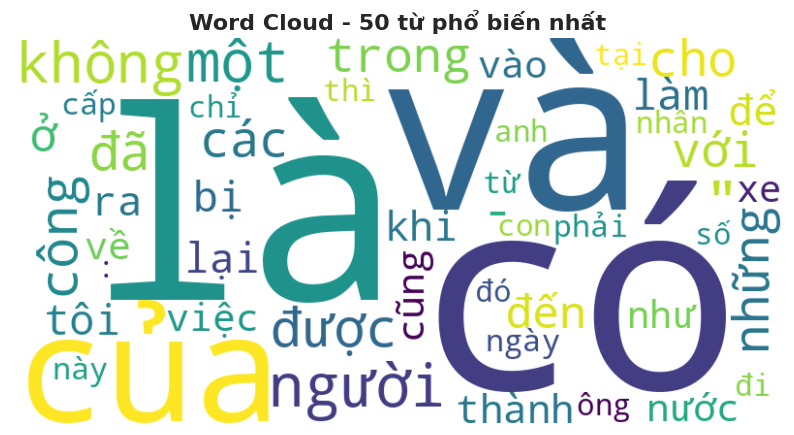

In [ ]:
plt.figure(figsize=(10, 6))
try:
    wordcloud = WordCloud(width=800, height=400,
                          background_color='white',
                          max_words=50).generate_from_frequencies(dict(all_words_counter.most_common(50)))
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title('Word Cloud - 50 từ phổ biến nhất', fontsize=16, fontweight='bold')
except ImportError:
    plt.text(0.5, 0.5, 'Vui lòng cài đặt thư viện: pip install wordcloud', ha='center', va='center')
plt.show()

Nhận xét:
- Các từ nối, chỉ từ phổ biến ("có", "và", "không", "các", "trong") chiếm kích thước lớn nhất. Điều này minh chứng dữ liệu được thu thập dưới dạng văn xuôi tự nhiên, giữ nguyên cấu trúc ngữ pháp thay vì các từ rời rạc.
- Sự xuất hiện dày đặc của đại từ nhân xưng ("tôi", "anh") và từ vựng giao tiếp cơ bản ("người", "làm", "đi") cho thấy tập dữ liệu mang tính liên kết ngữ nghĩa rất cao.

#### 3.2.5 Độ sáng và độ nét ảnh

In [26]:
df_img['dataset_short'] = df_img['dataset'].str.replace('UIT_HWDB_', '', regex=False)

fig = px.box(
        df_img,
        x='dataset_short',
        y='brightness_mean',
        points='outliers',
        color='dataset_short',
        title='<b>Phân bố độ sáng trung bình theo dataset</b>'
)
fig.update_layout(
        width=600,
        height=400,
        xaxis_title='Bộ dữ liệu',
        yaxis_title='Độ sáng trung bình (0-255)',
        showlegend=False,
        template='plotly_white'
)
fig.show(config={
    'toImageButtonOptions': {
        'format': 'svg',
        'filename': 'chart',
        'height': 400,
        'width': 600,
        'scale': 1
    }
})

fig = px.box(
        df_img,
        x='dataset_short',
        y='sharpness_score',
        points='outliers',
        color='dataset_short',
        title='<b>Phân bố độ nét ảnh (sharpness) theo dataset</b>'
)
fig.update_layout(
        width=600,
        height=400,
        xaxis_title='Bộ dữ liệu',
        yaxis_title='Sharpness score',
        showlegend=False,
        template='plotly_white'
)
fig.show(config={
    'toImageButtonOptions': {
        'format': 'svg',
        'filename': 'chart',
        'height': 400,
        'width': 600,
        'scale': 1
    }
})

#### 3.2.6 Trực quan hóa hình ảnh theo kích thước

Thực hiện hiển thị các ảnh mẫu đại diện từ mỗi bộ dữ liệu để quan sát trực quan dữ liệu.
- Duyệt qua danh sách all_info, tìm các file label.json trong từng dataset và chọn ngẫu nhiên một số cặp ảnh - nhãn hợp lệ.
- Thu thập các mẫu ảnh cùng thông tin tên dataset, đường dẫn ảnh và nội dung nhãn.
- Tạo bố cục lưới (subplot) để hiển thị nhiều ảnh cùng lúc.
- Mỗi ảnh được hiển thị kèm nhãn văn bản và kích thước ảnh (width × height) để dễ đánh giá dữ liệu.
- Thiết lập tiêu đề tổng cho toàn bộ hình và ẩn các trục để hình ảnh hiển thị rõ ràng hơn.

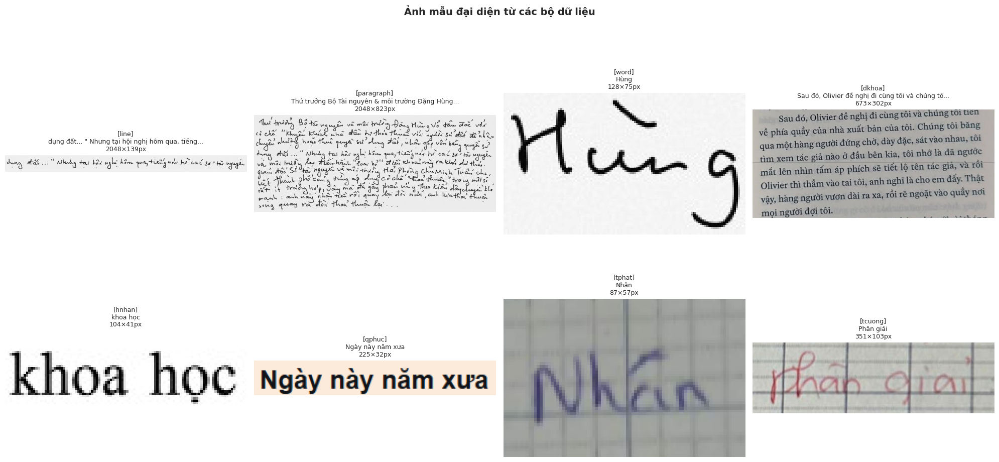

In [ ]:
def display_dataset_samples(all_info_list, n_per_dataset=1, random_seed=42):
    """Hiển thị ảnh mẫu đại diện từ mỗi bộ dữ liệu trong all_info."""
    mpl.rcParams['font.family'] = 'DejaVu Sans'
    random.seed(random_seed)

    collected_samples = []
    for info in all_info_list:
        dataset_path = CLEANED_DATA_DIR / info['dataset']
        # Giới hạn scan 5 subfolder đầu để nhanh
        label_files = sorted(dataset_path.rglob('label.json'))[:5]

        found = 0
        for lf in label_files:
            if found >= n_per_dataset:
                break
            try:
                with open(lf, 'r', encoding='utf-8') as f:
                    labels = json.load(f)
                folder = lf.parent
                valid_pairs = [(folder / k, v) for k, v in labels.items() if (folder / k).exists()]
                if valid_pairs:
                    pair = random.choice(valid_pairs[:min(len(valid_pairs), 20)])
                    collected_samples.append({
                        'dataset': info['dataset'].replace('UIT_HWDB_', ''),
                        'img_path': pair[0],
                        'label': pair[1]
                    })
                    found += 1
            except Exception:
                continue

    if not collected_samples:
        print("Không tìm thấy ảnh mẫu nào trong all_info.")
        return

    n_cols = min(4, len(collected_samples))
    n_rows = (len(collected_samples) + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
    axes_flat = np.array(axes).flatten() if (n_rows * n_cols) > 1 else [axes]

    for idx, item in enumerate(collected_samples):
        ax = axes_flat[idx]
        try:
            img = Image.open(item['img_path'])
            w, h = img.size
            ax.imshow(img, cmap='gray' if img.mode == 'L' else None)
            label = item['label']
            if len(label) > 50:
                label = label[:47] + '...'
            ax.set_title(f"[{item['dataset']}]\n{label}\n{w}×{h}px", fontsize=9, pad=6)
            ax.axis('off')
        except Exception:
            ax.text(0.5, 0.5, f"Lỗi tải ảnh", ha='center', va='center', color='red')
            ax.axis('off')

    for i in range(len(collected_samples), len(axes_flat)):
        axes_flat[i].axis('off')

    plt.suptitle('Ảnh mẫu đại diện từ các bộ dữ liệu', fontsize=14, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.show()

display_dataset_samples(all_info, n_per_dataset=1)


# 4. Chuẩn bị dữ liệu cho huấn luyện

Thực hiện **xây dựng tập dữ liệu Train/Test cho bài toán OCR** bằng cách kết hợp dữ liệu nhóm tự thu thập và dữ liệu từ bộ UIT.
- Thu thập toàn bộ dữ liệu nhóm từ các thư mục đã chỉ định và trích xuất ảnh cùng nhãn từ các file `label.json`.
- Đọc dữ liệu từ các bộ UIT (word, line, paragraph), sau đó xáo trộn và lấy 15 mẫu (5 word, 5 line, 5 paragraph) để tạo tập Test.
- Phần dữ liệu UIT còn lại được dùng để bổ sung vào tập Train nếu dữ liệu nhóm chưa đủ số lượng mục tiêu (1000 ảnh).
- Xáo trộn toàn bộ dữ liệu Train để đảm bảo tính ngẫu nhiên.
- Lưu tập Train theo cấu trúc nhiều thư mục con (mỗi thư mục chứa 50 ảnh và `label.json`) và lưu tập Test dưới dạng cấu trúc phẳng.
- Tạo lại cấu trúc thư mục dữ liệu trên Google Drive và lưu toàn bộ dataset đã chia.


In [ ]:
# Cấu hình
DRIVE_OCR = Path('/content/drive/MyDrive/IntroToML - OCR')
LOCAL_DATA = Path('/content/local_data')
OUTPUT_DIR = DRIVE_OCR / 'Data'

TARGET_TRAIN = 1000                 # Tổng số ảnh mục tiêu cho tập huấn luyện
IMAGES_PER_SUBFOLDER = 50           # Quy định số lượng ảnh trong mỗi thư mục con train
RANDOM_SEED = 42

# Danh sách nguồn dữ liệu nhóm
GROUP_DATA_SOURCES = [
    (DRIVE_OCR / 'tcuong', True),
    (DRIVE_OCR / 'qphuc', False),
    (DRIVE_OCR / 'tphat', False),
    (DRIVE_OCR / 'dkhoa', False),
    (DRIVE_OCR / 'hnhan', False),
]

# Định nghĩa các nguồn UIT
UIT_SOURCE_WORD = LOCAL_DATA / 'UIT_HWDB_word' / 'train_data'
UIT_SOURCE_LINE = LOCAL_DATA / 'UIT_HWDB_line' / 'train_data'
UIT_SOURCE_PARA = LOCAL_DATA / 'UIT_HWDB_paragraph' / 'train_data'

random.seed(RANDOM_SEED)

In [ ]:
# CÁC HÀM HỖ TRỢ XỬ LÝ
def collect_from_folder(folder_path):
    label_file = folder_path / 'label.json'
    if not label_file.exists():
        return []
    try:
        with open(label_file, 'r', encoding='utf-8') as f:
            content = f.read()
        content = re.sub(r',\s*}', '}', content)
        content = re.sub(r',\s*]', ']', content)
        labels = json.loads(content)
    except json.JSONDecodeError as e:
        print(f"Lỗi: Không thể giải mã JSON tại {folder_path}. Chi tiết: {e}")
        return []
    samples = []
    for img_name, label_text in labels.items():
        img_path = folder_path / img_name
        if img_path.exists():
            samples.append((img_path, label_text))
    return samples

def collect_group_data(sources):
    all_samples = []
    for folder_path, has_subfolders in sources:
        if not folder_path.exists(): continue
        if has_subfolders:
            for subfolder in sorted(folder_path.iterdir()):
                if subfolder.is_dir():
                    all_samples.extend(collect_from_folder(subfolder))
        else:
            all_samples.extend(collect_from_folder(folder_path))
    return all_samples

def collect_uit_by_type(source_path):
    samples = []
    if source_path.exists():
        for subfolder in sorted(source_path.iterdir()):
            if subfolder.is_dir():
                samples.extend(collect_from_folder(subfolder))
    return samples

def save_train_subfolders(samples, train_dir, per_folder):
    train_dir = Path(train_dir)
    train_dir.mkdir(parents=True, exist_ok=True)
    total_saved = 0
    folder_idx = 1
    for start in range(0, len(samples), per_folder):
        chunk = samples[start:start + per_folder]
        subfolder = train_dir / str(folder_idx)
        subfolder.mkdir(parents=True, exist_ok=True)
        labels = {}
        for idx, (img_path, label_text) in enumerate(chunk, 1):
            ext = img_path.suffix.lower()
            new_name = f"{idx}{ext}"
            shutil.copy2(str(img_path), str(subfolder / new_name))
            labels[new_name] = label_text
        with open(subfolder / 'label.json', 'w', encoding='utf-8') as f:
            json.dump(labels, f, ensure_ascii=False, indent=2)
        total_saved += len(chunk)
        folder_idx += 1
    return total_saved

def save_test_flat(samples, output_folder):
    output_folder = Path(output_folder)
    output_folder.mkdir(parents=True, exist_ok=True)
    labels = {}
    for idx, (img_path, label_text) in enumerate(samples, 1):
        ext = img_path.suffix.lower()
        new_name = f"{idx}{ext}"
        shutil.copy2(str(img_path), str(output_folder / new_name))
        labels[new_name] = label_text
    with open(output_folder / 'label.json', 'w', encoding='utf-8') as f:
        json.dump(labels, f, ensure_ascii=False, indent=2)

# Bước 1: Thu thập dữ liệu nhóm
print("BƯỚC 1: TỔNG HỢP DỮ LIỆU NHÓM TỰ THU THẬP (MANUAL)")
print("-" * 60)
group_samples = collect_group_data(GROUP_DATA_SOURCES)
print(f"    Tổng số dữ liệu Manual thu thập được: {len(group_samples)}")

# Bước 2: Trích xuất dữ liệu UIT theo tỉ lệ
print("BƯỚC 2: TRÍCH XUẤT DỮ LIỆU TỪ BỘ UIT THEO TỈ LỆ")
uit_word_all = collect_uit_by_type(UIT_SOURCE_WORD)
uit_line_all = collect_uit_by_type(UIT_SOURCE_LINE)
uit_para_all = collect_uit_by_type(UIT_SOURCE_PARA)

# Xáo trộn ngẫu nhiên từng danh sách
random.shuffle(uit_word_all)
random.shuffle(uit_line_all)
random.shuffle(uit_para_all)

# Lấy 5 mẫu cho mỗi loại để đưa vào tập Test
uit_test = uit_word_all[:5] + uit_line_all[:5] + uit_para_all[:5]

# Phần còn lại sẽ được sử dụng để bổ sung cho tập Train
uit_for_train = uit_word_all[5:] + uit_line_all[5:] + uit_para_all[5:]

print(f"    Thống kê mẫu UIT:")
print(f"    + Loại chữ (word): {len(uit_word_all)} mẫu")
print(f"    + Loại câu (line): {len(uit_line_all)} mẫu")
print(f"    + Loại đoạn (paragraph): {len(uit_para_all)} mẫu")
print(f"    Đã trích xuất 15 mẫu (5 chữ + 5 câu + 5 đoạn) cho tập Test.")

# Bước 3: Xây dựng tập Train
print("BƯỚC 3: XÂY DỰNG TẬP DỮ LIỆU HUÂN LUYỆN (TRAIN)")
train_samples = list(group_samples)
needed_from_uit = max(0, TARGET_TRAIN - len(train_samples))

if needed_from_uit > 0:
    # Trộn lại danh sách UIT còn lại để lấy ngẫu nhiên các loại cho tập train
    random.shuffle(uit_for_train)
    train_samples.extend(uit_for_train[:needed_from_uit])
    print(f"    Bổ sung: Đã lấy thêm {needed_from_uit} mẫu từ UIT để đủ 1000 ảnh.")

# Xáo trộn toàn bộ tập train lần cuối
random.shuffle(train_samples)

print(f"    Cấu trúc tập Train: {len(group_samples)} ảnh nhóm + {needed_from_uit} ảnh UIT.")
print(f"    Cấu trúc tập Test: 15 mẫu")

# Bước 4: Lưu trữ dữ liệu trên Google Drive
print("BƯỚC 4: KHỞI TẠO CẤU TRÚC THƯ MỤC DỮ LIỆU TRÊN DRIVE")

if OUTPUT_DIR.exists():
    shutil.rmtree(str(OUTPUT_DIR))

save_train_subfolders(train_samples, OUTPUT_DIR / 'train', IMAGES_PER_SUBFOLDER)
save_test_flat(uit_test, OUTPUT_DIR / 'test')

print("TIẾN TRÌNH HOÀN TẤT")
print(f"    Vị trí lưu trữ: {OUTPUT_DIR}")
print(f"    Tổng số lượng ảnh Train: {len(train_samples)}")
print(f"    Tổng số lượng ảnh Test: {len(uit_test)}")

------------------------------------------------------------
BƯỚC 1: TỔNG HỢP DỮ LIỆU NHÓM TỰ THU THẬP (MANUAL)
------------------------------------------------------------
Tổng số dữ liệu Manual thu thập được: 494

------------------------------------------------------------
BƯỚC 2: TRÍCH XUẤT DỮ LIỆU TỪ BỘ UIT THEO TỈ LỆ
------------------------------------------------------------
Thống kê mẫu UIT:
  + Loại chữ (word): 107602 mẫu
  + Loại câu (line): 7027 mẫu
  + Loại đoạn (paragraph): 1113 mẫu
Đã trích xuất 15 mẫu (5 chữ + 5 câu + 5 đoạn) cho tập Test.

------------------------------------------------------------
BƯỚC 3: XÂY DỰNG TẬP DỮ LIỆU HUÂN LUYỆN (TRAIN)
------------------------------------------------------------
Bổ sung: Đã lấy thêm 506 mẫu từ UIT để đủ 1000 ảnh.
Cấu trúc tập Train: 494 ảnh nhóm + 506 ảnh UIT.
Cấu trúc tập Test: 15 mẫu

------------------------------------------------------------
BƯỚC 4: KHỞI TẠO CẤU TRÚC THƯ MỤC DỮ LIỆU TRÊN DRIVE
--------------------------